In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
#plt.rcParams['axes.grid'] = True

In [3]:
def string_to_float_list(data_string: str):
    return np.array([float(x) for x in data_string.split()])

In [4]:
c = 299792458 # m / s

grating_width = 0.002 #mm

rydberg_constant = 10973731.6 #m^-1

In [5]:
L = 814.0
L_err = 1.0

#y_He = np.array([185.8, 212.3, 252.0, 266.6, 291.2])

y_He = np.array([185.8, 212.3, 252.0, 291.2])
y_He_err = np.ones(len(y_He)) * 3.6

y_H = np.array([182.8, 206.0, 290.7])
y_H_err = np.ones(len(y_H)) * 3.6

He_D3_y_vals = np.array([247.1, 256.9, 249.0, 259.1])

He_D3_y = np.mean(He_D3_y_vals)
He_D3_y_err = np.std(He_D3_y_vals) / np.sqrt(len(He_D3_y_vals))


In [6]:
H_wavelengths = y_H * grating_width / np.sqrt(L**2+y_H**2) * 1e6
H_wavelengths_err = 1e6 * np.sqrt( ((grating_width*L**2) / (L**2 + y_H**2)**(3/2) * y_H_err)**2 + ((grating_width*L*y_H) / (L**2 + y_H**2)**(3/2) * L_err)**2 )
inverse_H_wavelength_err = H_wavelengths_err / (H_wavelengths**2)
H_n_vals = np.array([5, 4, 3])

He_wavelengths = y_He * grating_width / np.sqrt(L**2+y_He**2) * 1e6
He_wavelengths_err = 1e6 * np.sqrt( ((grating_width*L**2) / (L**2 + y_He**2)**(3/2) * y_He_err)**2 + ((grating_width*L*y_He) / (L**2 + y_He**2)**(3/2) * L_err)**2 )
inverse_He_wavelength_err = He_wavelengths_err / (He_wavelengths**2)
He_n_vals = np.array([4, 4, 3, 3])


In [7]:
def linear_fit(x, m):
    return m*(1/4 - x)

popt, pcov = scipy.optimize.curve_fit(linear_fit, 1 / H_n_vals**2, 1 / H_wavelengths, sigma=inverse_H_wavelength_err)

slope = popt[0]
slope_err = np.sqrt(pcov[0][0])


popt_He, pcov_He = scipy.optimize.curve_fit(linear_fit, 1 / He_n_vals**2, 1 / He_wavelengths, sigma=inverse_He_wavelength_err)

slope_He = popt_He[0]
slope_He_err = np.sqrt(pcov_He[0][0])

# offset = popt[1]
# offset_err = np.sqrt(pcov[1][1])

# slope_err = np.sqrt((1/3) * np.sum(1/H_wavelengths - slope/(H_n_vals**2)))

0.4196400718901242


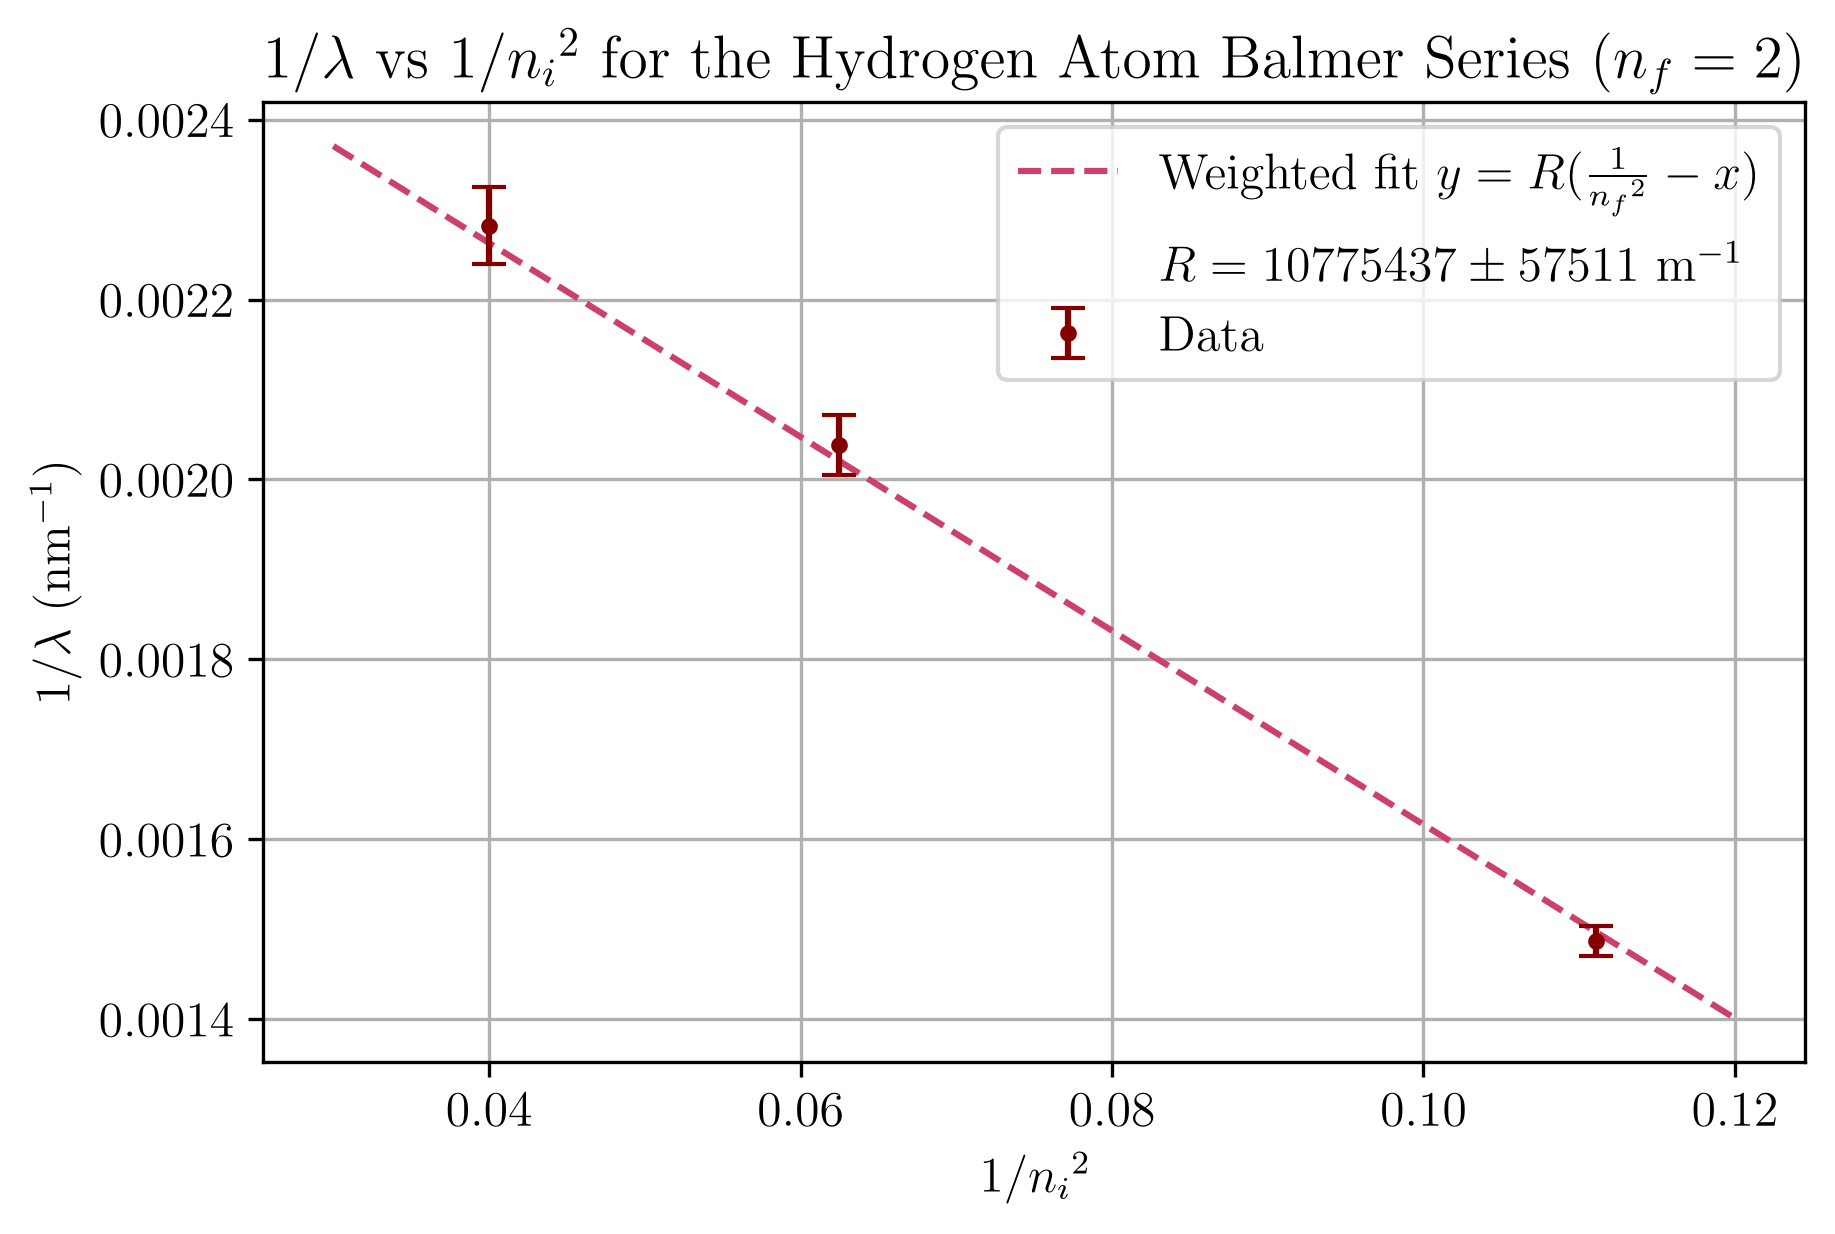

In [8]:
H_fig, H_ax = plt.subplots(1, figsize=(6, 4), layout="constrained")

H_ax.errorbar(1 / H_n_vals**2, 1 / H_wavelengths, inverse_H_wavelength_err, fmt = 'o', markersize = 3, capsize = 4, color = 'xkcd:dark red', zorder=10, label = "Data")

x_vals = np.linspace(0.03, 0.12, 10)
H_ax.plot(x_vals, linear_fit(x_vals, slope), color = 'xkcd:dark pink', linestyle='dashed', label = rf"Weighted fit $y = R(\frac{{1}}{{{{n_f}}^2}} - x)$")
H_ax.plot(x_vals, linear_fit(x_vals, slope), color = 'none', label = rf"$R = {1e9*slope:0.0f} \pm {1e9*slope_err:0.0f}$ m$^{{-1}}$")

H_ax.grid()
H_ax.legend()
H_ax.set_title(r"$1/\lambda$ vs $1/{n_i}^2$ for the Hydrogen Atom Balmer Series $(n_f = 2)$")
H_ax.set_xlabel(r"$1 / {n_i}^2$")
H_ax.set_ylabel(r"$1 / \lambda$ (nm$^{-1}$)")

#H_ax.set_ylim(0, 0.0025)

H_fig.savefig("plots/hydrogen_linear.png", dpi=300)


chi2 = np.sum((1/H_wavelengths - linear_fit(1 / H_n_vals**2, slope))**2 / inverse_H_wavelength_err**2)
reduced_chi2 = chi2 / (len(H_wavelengths)-1)

print(reduced_chi2)

1.008913606763839
36.31018888072383


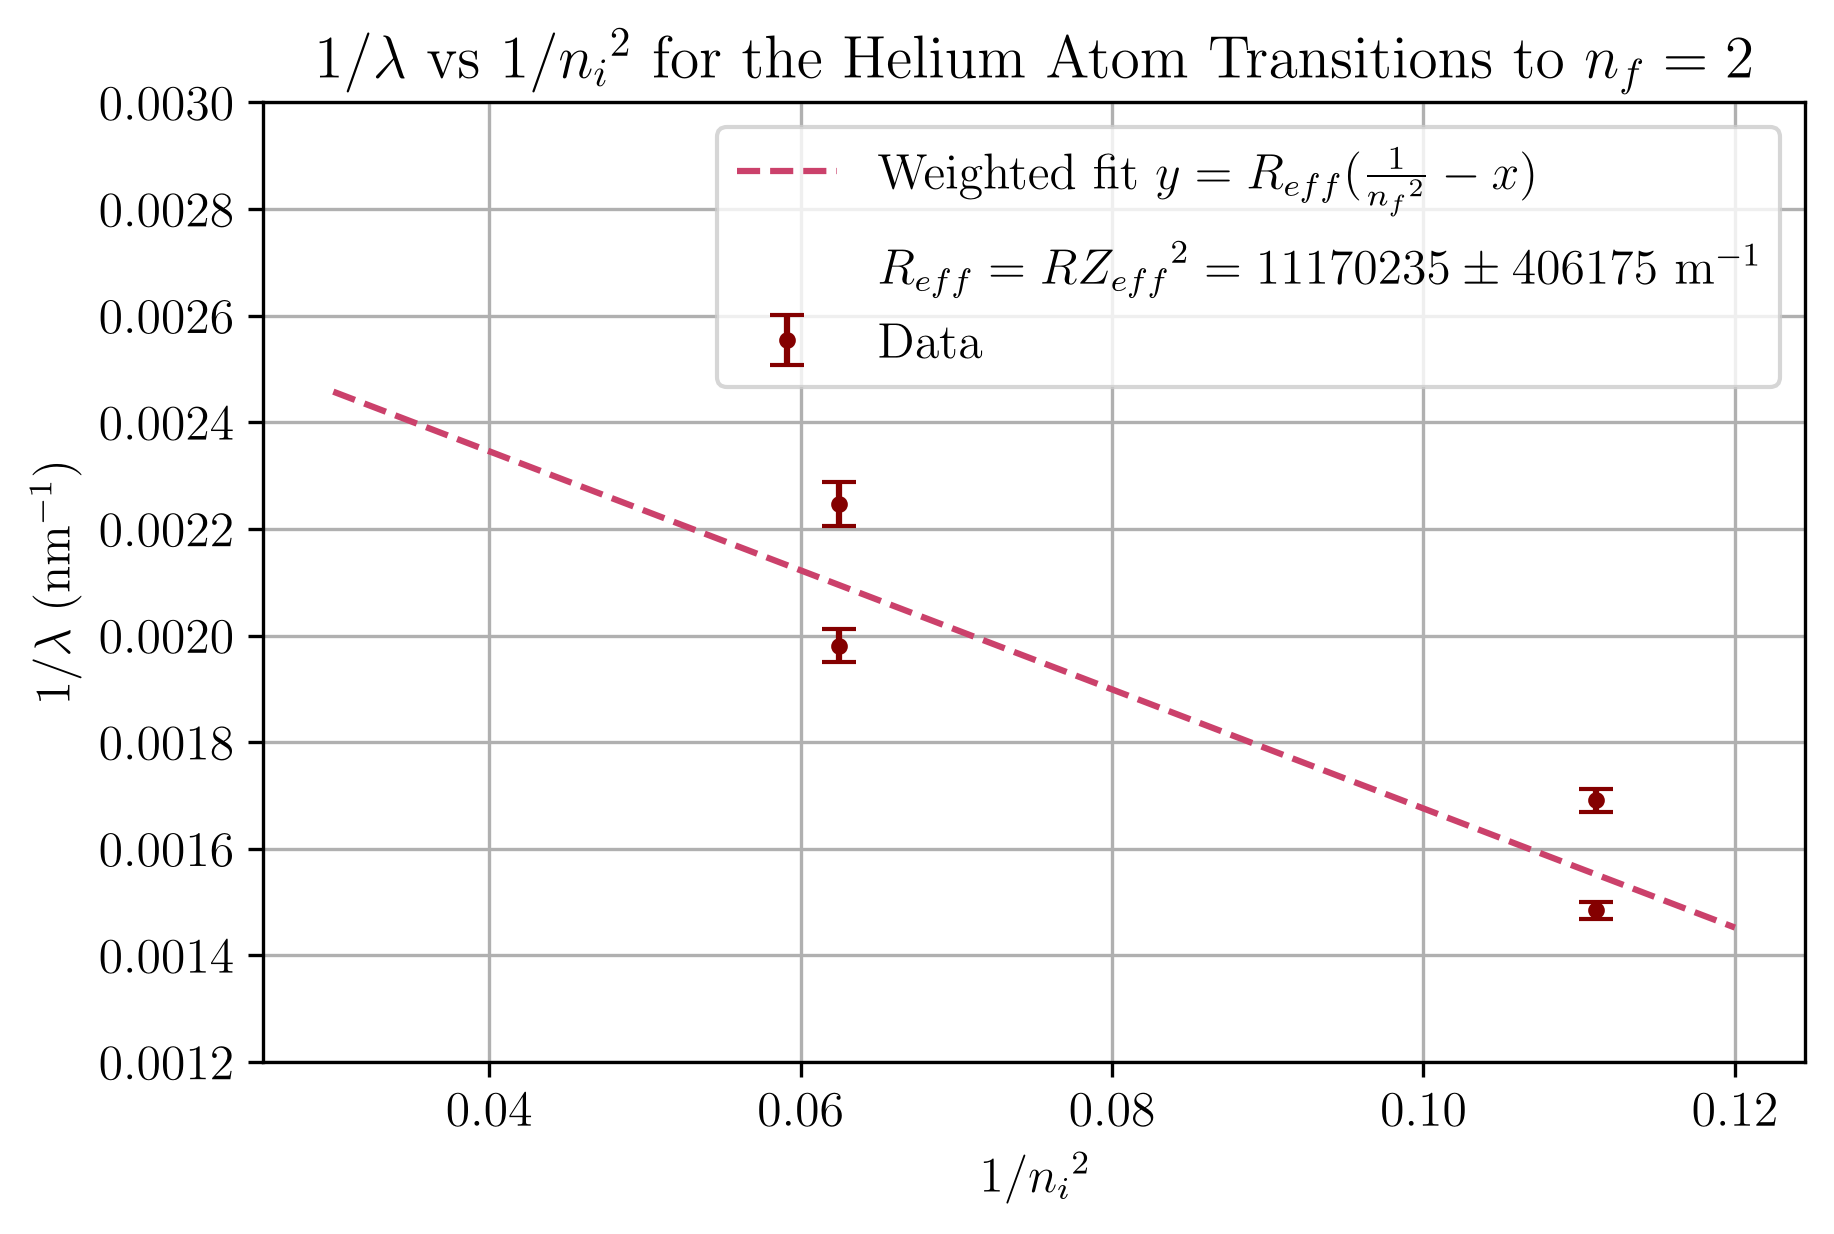

In [13]:
He_fig, He_ax = plt.subplots(1, figsize=(6, 4), layout="constrained")

He_ax.errorbar(1 / He_n_vals**2, 1 / He_wavelengths, inverse_He_wavelength_err, fmt = 'o', markersize = 3, capsize = 4, color = 'xkcd:dark red', zorder=10, label = "Data")

x_vals = np.linspace(0.03, 0.12, 10)
He_ax.plot(x_vals, linear_fit(x_vals, slope_He), color = 'xkcd:dark pink', linestyle='dashed', label = rf"Weighted fit $y = R_{{eff}}(\frac{{1}}{{{{n_f}}^2}} - x)$")
He_ax.plot(x_vals, linear_fit(x_vals, slope_He), color = 'none', label = rf"$R_{{eff}} = R{{Z_{{eff}}}}^2 = {1e9*slope_He:0.0f} \pm {1e9*slope_He_err:0.0f}$ m$^{{-1}}$")

He_ax.grid()
He_ax.legend()
He_ax.set_title(r"$1/\lambda$ vs $1/{n_i}^2$ for the Helium Atom Transitions to $n_f = 2$")
He_ax.set_xlabel(r"$1 / {n_i}^2$")
He_ax.set_ylabel(r"$1 / \lambda$ (nm$^{-1}$)")

He_ax.set_ylim(0.0012, 0.003)

He_fig.savefig("plots/helium_linear.png", dpi=300)

#print(1e9 * slope_He / (2 * rydberg_constant))

Ze = np.sqrt(1e9 * slope_He / rydberg_constant)

print(Ze)

chi2_He = np.sum((1/He_wavelengths - linear_fit(1 / He_n_vals**2, slope))**2 / inverse_He_wavelength_err**2)
reduced_chi2_He = chi2_He / (len(He_wavelengths)-1)

print(reduced_chi2_He)